# Fase 5: Red Neuronal con Keras Tuner (Deep Learning)
**Tesis:** Modelo Predictivo de Resultados — Premier League 2017–2025
**Objetivo:** Implementar una red neuronal en **Keras/TensorFlow** y optimizar su arquitectura e hiperparámetros con **Keras Tuner**, evaluándola con la misma validación temporal (expanding window, 7 folds) que el resto de los modelos.
**Input:** `Dataset/model_dataset_selected.csv` (datos corregidos, sin duplicados ni fechas invertidas)
**Output:** `resultados/keras_tuner_*.csv`, `resultados/models_keras/*.keras`, `Imagenes/keras_tuner/*.png`

---

## ¿Qué es Keras Tuner?
Es una librería que **busca automáticamente** la mejor arquitectura de una red neuronal (nº de capas, neuronas, dropout, learning rate, etc.). En `04_tuning.ipynb` la red PyTorch solo probó **3 configuraciones a mano**; aquí el tuner explora el espacio de forma sistemática con **optimización bayesiana**: cada nueva configuración se elige usando lo aprendido de las anteriores, lo que necesita menos pruebas que una búsqueda aleatoria.

## Diferencias metodológicas respecto de la red PyTorch de `04_tuning`
| Aspecto | PyTorch (`04_tuning`) | Keras Tuner (este notebook) |
|---|---|---|
| Búsqueda | 3 configuraciones manuales | Optimización bayesiana, 20 configuraciones por fold |
| Validación para early stopping | **El set de test** (fuga leve) | **Último 20 % cronológico del train** (el test nunca se usa para decidir) |
| Escalado | `StandardScaler` por fold | `StandardScaler` por fold, ajustado solo con train |

## Promedio de varias redes (decisión metodológica, con su origen)
Una primera corrida entrenó **una sola red** por fold. El resultado fue muy inestable: en el fold 1, que tiene solo 347 partidos de entrenamiento, el accuracy fue 41 % y el AUC 0,44 (peor que el azar), y el promedio de los 7 folds quedó en 63,3 % ± 10. Al diagnosticarlo se vio que **no era un error de datos sino varianza de inicialización**: la misma configuración repetida con 10 semillas distintas dio AUC entre 0,47 y 0,72 en ese fold.

La corrección estándar es **entrenar 10 redes con semillas distintas y promediar sus probabilidades**, que se aplica igual a los 7 folds. Es importante ser transparente: esta decisión se tomó **después de observar el fold 1**, no antes; no se eligió por rendimiento (no se escogió la mejor semilla) y la primera corrida se conserva en `resultados/previo_keras_una_semilla/`. Las columnas `auc_semilla_min` y `auc_semilla_max` muestran cuánto varía cada red individual dentro de cada fold.

## Referencias de comparación
Además de los modelos de `04_tuning`, se incluye una **regresión logística solo con las 3 probabilidades de las cuotas**. Sirve para ver cuánto aporta cualquier modelo más allá del mercado.

## 1. Configuración y carga de datos

In [1]:
import os, sys, json, time, warnings
warnings.filterwarnings('ignore')
os.environ['TF_CPP_MIN_LOG_LEVEL'] = '2'

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import tensorflow as tf
import keras
from keras import layers, regularizers
import keras_tuner as kt

from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.utils.class_weight import compute_class_weight
from sklearn.calibration import calibration_curve
from sklearn.metrics import roc_auc_score

sys.path.insert(0, '.')
from utils.split_utils import expanding_window_split, print_fold_summary
from utils.evaluation_utils import evaluate_model, leer_baseline

sns.set_theme(style='whitegrid', palette='muted')
plt.rcParams['figure.dpi'] = 120

SEED = 42
keras.utils.set_random_seed(SEED)
TARGET = 'target_home_win'

# Baseline del mercado calculado en 01_eda (regla: local si P(local) > P(visitante)).
# Para comparar con los modelos se usa el promedio de las MISMAS 7 temporadas de test.
BASELINE_TODAS = leer_baseline()
with open('resultados/baseline_mercado_por_temporada.json', encoding='utf-8') as f:
    BASELINE_MERCADO = json.load(f)['baseline_temporadas_test_promedio']

for d in ['resultados/models_keras', 'resultados/keras_tuner', 'Imagenes/keras_tuner']:
    os.makedirs(d, exist_ok=True)

print(f'TensorFlow {tf.__version__} | Keras {keras.__version__} | Keras Tuner {kt.__version__}')
print(f'Baseline mercado (7 temporadas de test): {BASELINE_MERCADO:.4f}')

TensorFlow 2.21.0 | Keras 3.15.1 | Keras Tuner 1.4.8
Baseline mercado (7 temporadas de test): 0.6436


In [2]:
df = pd.read_csv('Dataset/model_dataset_selected.csv')
folds = expanding_window_split(df, min_train_seasons=1)
print_fold_summary(folds, df)

X = df.drop(columns=[TARGET, 'season'])
y = df[TARGET]
print(f'\nFilas: {len(df):,} | Features: {X.shape[1]} | Victorias locales: {y.mean()*100:.1f}%')

# Referencia: solo las 3 probabilidades implícitas de las cuotas (misma alineación por posición)
enr = pd.read_csv('Dataset/model_dataset_enriched.csv')
assert len(enr) == len(df) and (enr[TARGET].values == y.values).all()
CUOTAS = enr[['odds_home_prob', 'odds_draw_prob', 'odds_away_prob']]

RESUMEN DE FOLDS — EXPANDING WINDOW
Total de partidos: 2973
Total de folds: 7

Fold 1:
  Train: ['2017-2018']
         347 partidos (11.7%)
  Test:  2018-2019
         371 partidos (12.5%)

Fold 2:
  Train: ['2017-2018', '2018-2019']
         718 partidos (24.2%)
  Test:  2019-2020
         371 partidos (12.5%)

Fold 3:
  Train: ['2017-2018', '2018-2019', '2019-2020']
         1089 partidos (36.6%)
  Test:  2020-2021
         377 partidos (12.7%)

Fold 4:
  Train: ['2017-2018', '2018-2019', '2019-2020', '2020-2021']
         1466 partidos (49.3%)
  Test:  2021-2022
         377 partidos (12.7%)

Fold 5:
  Train: ['2017-2018', '2018-2019', '2019-2020', '2020-2021', '2021-2022']
         1843 partidos (62.0%)
  Test:  2022-2023
         377 partidos (12.7%)

Fold 6:
  Train: ['2017-2018', '2018-2019', '2019-2020', '2020-2021', '2021-2022', '2022-2023']
         2220 partidos (74.7%)
  Test:  2023-2024
         376 partidos (12.6%)

Fold 7:
  Train: ['2017-2018', '2018-2019', '2019-2020',

## 2. Definición del HyperModel
El `HyperModel` describe el **espacio de búsqueda**: cada `hp.Int / hp.Choice / hp.Float` declara un hiperparámetro que el tuner puede variar.

| Hiperparámetro | Rango |
|---|---|
| `n_layers` | 1 – 3 capas ocultas |
| `units_i` | 16 – 128 neuronas (paso 16) por capa |
| `activation` | relu, elu, swish |
| `batch_norm` | sí / no |
| `dropout` | 0.0 – 0.5 |
| `l2` | 1e-5 – 1e-2 (escala log) |
| `optimizer` | adam, adamw, rmsprop |
| `learning_rate` | 1e-4 – 1e-2 (escala log) |
| `batch_size` | 32, 64, 128 |
| `balanced_weights` | pesos de clase balanceados sí / no |

La salida es una neurona **sigmoide** (probabilidad de victoria local) y la pérdida es *binary cross-entropy*, igual que la red PyTorch. Con ~2.900 filas se limita el tamaño máximo de la red para reducir el sobreajuste.

In [3]:
class FootballHyperModel(kt.HyperModel):
    def __init__(self, n_features, class_weight=None):
        super().__init__()
        self.n_features = n_features
        self.class_weight = class_weight

    def build(self, hp):
        act = hp.Choice('activation', ['relu', 'elu', 'swish'])
        use_bn = hp.Boolean('batch_norm')
        drop = hp.Float('dropout', 0.0, 0.5, step=0.1)
        l2 = hp.Float('l2', 1e-5, 1e-2, sampling='log')

        inputs = keras.Input(shape=(self.n_features,))
        x = inputs
        for i in range(hp.Int('n_layers', 1, 3)):
            x = layers.Dense(hp.Int(f'units_{i}', 16, 128, step=16),
                             kernel_regularizer=regularizers.l2(l2))(x)
            if use_bn:
                x = layers.BatchNormalization()(x)
            x = layers.Activation(act)(x)
            x = layers.Dropout(drop)(x)
        outputs = layers.Dense(1, activation='sigmoid')(x)
        model = keras.Model(inputs, outputs)

        lr = hp.Float('learning_rate', 1e-4, 1e-2, sampling='log')
        opt_name = hp.Choice('optimizer', ['adam', 'adamw', 'rmsprop'])
        opt = {'adam': keras.optimizers.Adam, 'adamw': keras.optimizers.AdamW,
               'rmsprop': keras.optimizers.RMSprop}[opt_name](learning_rate=lr)

        model.compile(optimizer=opt, loss='binary_crossentropy',
                      metrics=['accuracy', keras.metrics.AUC(name='auc')])
        return model

    def fit(self, hp, model, *args, **kwargs):
        batch = hp.Choice('batch_size', [32, 64, 128])
        use_cw = hp.Boolean('balanced_weights')
        return model.fit(*args, batch_size=batch,
                         class_weight=self.class_weight if use_cw else None, **kwargs)

_hp = kt.HyperParameters()
FootballHyperModel(X.shape[1]).build(_hp)
print(f'Hiperparámetros en el espacio de búsqueda: {len(_hp.space)}')

Hiperparámetros en el espacio de búsqueda: 8


## 3. Tuning por fold (Expanding Window)
Para **cada fold**:
1. Se ajusta el `StandardScaler` **solo con el train**.
2. El **último 20 % cronológico del train** se separa como validación (el tuner y el early stopping lo usan para decidir; el test no se toca).
3. La **optimización bayesiana** busca la mejor arquitectura minimizando `val_loss`.
4. Con los mejores hiperparámetros se reentrena sobre el **train completo** durante la mejor época encontrada, y recién ahí se evalúa en la temporada de test.

In [4]:
MAX_TRIALS = 20        # configuraciones evaluadas por fold
MAX_EPOCHS = 40        # épocas máximas por configuración
PATIENCE = 6
VAL_FRAC = 0.20
N_SEMILLAS = 10        # redes con distinta inicialización que se promedian en cada fold

def make_callbacks():
    return [keras.callbacks.EarlyStopping(monitor='val_loss', patience=PATIENCE, restore_best_weights=True),
            keras.callbacks.ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=3, min_lr=1e-6)]

all_results, best_hps_by_fold, histories, test_preds, ref_results = [], {}, {}, {}, []
total_start = time.time()

for fold_idx, (train_idx, test_idx, train_s, test_s) in enumerate(folds):
    fold = fold_idx + 1
    t0 = time.time()
    print(f'\n--- FOLD {fold}/{len(folds)} --- Train: {len(train_idx)} | Test {test_s}: {len(test_idx)}')

    X_tr_raw, y_tr = X.iloc[train_idx], y.iloc[train_idx].values
    X_te_raw, y_te = X.iloc[test_idx], y.iloc[test_idx]

    scaler = StandardScaler().fit(X_tr_raw)
    X_tr, X_te = scaler.transform(X_tr_raw), scaler.transform(X_te_raw)

    # Split cronológico interno (el orden del dataset es temporal)
    n_val = int(len(X_tr) * VAL_FRAC)
    X_sub, y_sub = X_tr[:-n_val], y_tr[:-n_val]
    X_val, y_val = X_tr[-n_val:], y_tr[-n_val:]

    cw = dict(zip([0, 1], compute_class_weight('balanced', classes=np.array([0, 1]), y=y_sub)))

    tuner = kt.BayesianOptimization(
        FootballHyperModel(X.shape[1], class_weight=cw),
        objective='val_loss', max_trials=MAX_TRIALS, num_initial_points=6,
        directory='resultados/keras_tuner', project_name=f'fold{fold}',
        overwrite=True, seed=SEED)

    tuner.search(X_sub, y_sub, validation_data=(X_val, y_val),
                 epochs=MAX_EPOCHS, callbacks=make_callbacks(), verbose=0)

    best_hp = tuner.get_best_hyperparameters(1)[0]
    n_trials = len(tuner.oracle.trials)

    # Mejor época: reentrenar la mejor config en train_sub y ver dónde minimiza val_loss
    keras.utils.set_random_seed(SEED)
    m_probe = tuner.hypermodel.build(best_hp)
    h_probe = tuner.hypermodel.fit(best_hp, m_probe, X_sub, y_sub, validation_data=(X_val, y_val),
                                   epochs=MAX_EPOCHS, callbacks=make_callbacks(), verbose=0)
    best_epoch = int(np.argmin(h_probe.history['val_loss']) + 1)
    histories[fold] = pd.DataFrame(h_probe.history)

    # Reentrenar en TODO el train con esa cantidad de épocas, con N_SEMILLAS inicializaciones distintas,
    # y promediar sus probabilidades (reduce la varianza de la inicialización con pocos datos)
    cw_full = dict(zip([0, 1], compute_class_weight('balanced', classes=np.array([0, 1]), y=y_tr)))
    probs, aucs_semilla = [], []
    for k in range(N_SEMILLAS):
        keras.utils.set_random_seed(SEED + k)
        final_hm = FootballHyperModel(X.shape[1], class_weight=cw_full)
        model = final_hm.build(best_hp)
        final_hm.fit(best_hp, model, X_tr, y_tr, epochs=max(best_epoch, 5), verbose=0)
        pk = model.predict(X_te, verbose=0).ravel()
        probs.append(pk); aucs_semilla.append(roc_auc_score(y_te, pk))   # solo diagnóstico de varianza, no se usa para elegir
        model.save(f'resultados/models_keras/keras_fold{fold}_semilla{k}.keras')

    y_proba = np.mean(probs, axis=0)
    y_pred = (y_proba >= 0.5).astype(int)
    test_preds[fold] = (y_te.values, y_proba)

    m = evaluate_model(y_te, y_pred, y_proba, 'Red Neuronal (Keras Tuner)')
    m.update({'fold': fold, 'train_seasons': str(train_s), 'test_season': str(test_s),
              'n_trials': n_trials, 'best_epoch': best_epoch,
              'val_loss_tuner': float(h_probe.history['val_loss'][best_epoch - 1]),
              'auc_semilla_min': min(aucs_semilla), 'auc_semilla_max': max(aucs_semilla),
              'best_params': json.dumps(best_hp.values), 'fit_time': time.time() - t0})
    all_results.append(m)
    best_hps_by_fold[fold] = best_hp.values

    # Referencia: regresión logística solo con cuotas, mismo fold
    ref = make_pipeline(StandardScaler(), LogisticRegression(C=1.0, max_iter=2000, class_weight='balanced')).fit(CUOTAS.iloc[train_idx], y_tr)
    pr = ref.predict_proba(CUOTAS.iloc[test_idx])[:, 1]
    mr = evaluate_model(y_te, (pr >= 0.5).astype(int), pr, 'Solo cuotas (Reg. Logística)'); mr['fold'] = fold
    ref_results.append(mr)

    print(f'   Trials: {n_trials} | mejor época: {best_epoch} | Acc: {m["accuracy"]:.4f} | '
          f'F1: {m["f1_score"]:.4f} | AUC: {m["roc_auc"]:.4f} | Brier: {m["brier_score"]:.4f}  (solo cuotas: Acc {mr["accuracy"]:.4f}, AUC {mr["roc_auc"]:.4f})')
    print(f'   HP: {best_hp.values}')
    print(f'   Fold en {time.time()-t0:.0f}s')

print(f'\nTUNING COMPLETADO — {(time.time()-total_start)/60:.1f} minutos')


--- FOLD 1/7 --- Train: 347 | Test 2018-2019: 371


   Trials: 20 | mejor época: 4 | Acc: 0.6577 | F1: 0.5753 | AUC: 0.6811 | Brier: 0.2288  (solo cuotas: Acc 0.6765, AUC 0.7508)
   HP: {'activation': 'elu', 'batch_norm': False, 'dropout': 0.2, 'l2': 1e-05, 'n_layers': 3, 'units_0': 16, 'learning_rate': 0.0024213008585778108, 'optimizer': 'adamw', 'units_1': 16, 'units_2': 16, 'batch_size': 32, 'balanced_weights': False}
   Fold en 147s

--- FOLD 2/7 --- Train: 718 | Test 2019-2020: 371


   Trials: 20 | mejor época: 9 | Acc: 0.6415 | F1: 0.5857 | AUC: 0.7005 | Brier: 0.2236  (solo cuotas: Acc 0.6739, AUC 0.7076)
   HP: {'activation': 'swish', 'batch_norm': False, 'dropout': 0.30000000000000004, 'l2': 8.646662520401125e-05, 'n_layers': 1, 'units_0': 16, 'learning_rate': 0.008270321384830361, 'optimizer': 'rmsprop', 'units_1': 128, 'units_2': 64, 'batch_size': 32, 'balanced_weights': False}
   Fold en 181s

--- FOLD 3/7 --- Train: 1089 | Test 2020-2021: 377


   Trials: 20 | mejor época: 40 | Acc: 0.6817 | F1: 0.6053 | AUC: 0.7098 | Brier: 0.2197  (solo cuotas: Acc 0.6897, AUC 0.7247)
   HP: {'activation': 'relu', 'batch_norm': False, 'dropout': 0.0, 'l2': 1e-05, 'n_layers': 1, 'units_0': 16, 'learning_rate': 0.0001, 'optimizer': 'rmsprop', 'units_1': 128, 'units_2': 128, 'batch_size': 32, 'balanced_weights': False}
   Fold en 225s

--- FOLD 4/7 --- Train: 1466 | Test 2021-2022: 377


   Trials: 20 | mejor época: 4 | Acc: 0.6976 | F1: 0.6096 | AUC: 0.7449 | Brier: 0.2043  (solo cuotas: Acc 0.6711, AUC 0.7541)
   HP: {'activation': 'swish', 'batch_norm': False, 'dropout': 0.30000000000000004, 'l2': 1e-05, 'n_layers': 3, 'units_0': 112, 'learning_rate': 0.00949586161525601, 'optimizer': 'adam', 'units_1': 16, 'units_2': 16, 'batch_size': 32, 'balanced_weights': False}
   Fold en 188s

--- FOLD 5/7 --- Train: 1843 | Test 2022-2023: 377


   Trials: 20 | mejor época: 6 | Acc: 0.6446 | F1: 0.5759 | AUC: 0.7002 | Brier: 0.2249  (solo cuotas: Acc 0.6711, AUC 0.7245)
   HP: {'activation': 'swish', 'batch_norm': True, 'dropout': 0.4, 'l2': 1e-05, 'n_layers': 1, 'units_0': 32, 'learning_rate': 0.01, 'optimizer': 'adam', 'units_1': 128, 'units_2': 16, 'batch_size': 32, 'balanced_weights': False}
   Fold en 194s

--- FOLD 6/7 --- Train: 2220 | Test 2023-2024: 376


   Trials: 20 | mejor época: 7 | Acc: 0.6835 | F1: 0.6490 | AUC: 0.7481 | Brier: 0.2089  (solo cuotas: Acc 0.6915, AUC 0.7574)
   HP: {'activation': 'relu', 'batch_norm': False, 'dropout': 0.4, 'l2': 1e-05, 'n_layers': 3, 'units_0': 112, 'learning_rate': 0.00201851676146538, 'optimizer': 'adam', 'units_1': 16, 'units_2': 16, 'batch_size': 32, 'balanced_weights': True}
   Fold en 240s

--- FOLD 7/7 --- Train: 2596 | Test 2024-2025: 377


   Trials: 20 | mejor época: 18 | Acc: 0.6711 | F1: 0.6051 | AUC: 0.7242 | Brier: 0.2091  (solo cuotas: Acc 0.6631, AUC 0.7313)
   HP: {'activation': 'elu', 'batch_norm': False, 'dropout': 0.30000000000000004, 'l2': 3.235784315073516e-05, 'n_layers': 1, 'units_0': 112, 'learning_rate': 0.0008593518059927045, 'optimizer': 'adamw', 'units_1': 64, 'units_2': 16, 'batch_size': 32, 'balanced_weights': False}
   Fold en 224s

TUNING COMPLETADO — 23.3 minutos


## 4. Resultados por fold

In [5]:
df_k = pd.DataFrame(all_results)
df_k.to_csv('resultados/keras_tuner_results_detailed.csv', index=False)
df_ref = pd.DataFrame(ref_results)
df_ref.to_csv('resultados/solo_cuotas_results_detailed.csv', index=False)

cols = ['fold', 'test_season', 'accuracy', 'f1_score', 'roc_auc', 'brier_score', 'n_trials', 'best_epoch', 'auc_semilla_min', 'auc_semilla_max']
print(df_k[cols].round(4).to_string(index=False))

 fold test_season  accuracy  f1_score  roc_auc  brier_score  n_trials  best_epoch  auc_semilla_min  auc_semilla_max
    1   2018-2019    0.6577    0.5753   0.6811       0.2288        20           4           0.4442           0.7236
    2   2019-2020    0.6415    0.5857   0.7005       0.2236        20           9           0.6747           0.7074
    3   2020-2021    0.6817    0.6053   0.7098       0.2197        20          40           0.6290           0.7028
    4   2021-2022    0.6976    0.6096   0.7449       0.2043        20           4           0.7037           0.7500
    5   2022-2023    0.6446    0.5759   0.7002       0.2249        20           6           0.6801           0.7120
    6   2023-2024    0.6835    0.6490   0.7481       0.2089        20           7           0.7268           0.7521
    7   2024-2025    0.6711    0.6051   0.7242       0.2091        20          18           0.7189           0.7277


### Mejores hiperparámetros por fold
Si el tuner converge a configuraciones parecidas en distintos folds, el hallazgo es robusto; si cambian mucho, el espacio de búsqueda es "plano" (esperable con ~2.900 filas).

In [6]:
hp_df = pd.DataFrame(best_hps_by_fold).T
hp_df.index.name = 'fold'
print(hp_df.to_string())
hp_df.to_csv('resultados/keras_tuner_best_hps.csv')

     activation batch_norm dropout        l2 n_layers units_0 learning_rate optimizer units_1 units_2 batch_size balanced_weights
fold                                                                                                                             
1           elu      False     0.2   0.00001        3      16      0.002421     adamw      16      16         32            False
2         swish      False     0.3  0.000086        1      16       0.00827   rmsprop     128      64         32            False
3          relu      False     0.0   0.00001        1      16        0.0001   rmsprop     128     128         32            False
4         swish      False     0.3   0.00001        3     112      0.009496      adam      16      16         32            False
5         swish       True     0.4   0.00001        1      32          0.01      adam     128      16         32            False
6          relu      False     0.4   0.00001        3     112      0.002019      adam     

## 5. Resumen promedio (± desviación estándar entre folds)

In [7]:
def resumir(d, nombre):
    s = d[['accuracy', 'f1_score', 'roc_auc', 'brier_score']].agg(['mean', 'std']).T
    fila = {f'{m}_{k}': round(s.loc[m, k], 4) for m in s.index for k in ['mean', 'std']}
    return pd.DataFrame([fila], index=pd.Index([nombre], name='model'))

summary_k = resumir(df_k, 'Red Neuronal (Keras Tuner)')
summary_ref = resumir(df_ref, 'Solo cuotas (Reg. Logística)')
summary_k.to_csv('resultados/keras_tuner_results.csv')

print('RED NEURONAL (KERAS TUNER) — Promedio sobre 7 folds')
print('=' * 62)
for m, lab in [('accuracy', 'Accuracy'), ('f1_score', 'F1-Score'), ('roc_auc', 'ROC-AUC'), ('brier_score', 'Brier')]:
    print(f'  {lab:<10}: {summary_k.loc[summary_k.index[0], m + "_mean"]:.4f} ± {summary_k.loc[summary_k.index[0], m + "_std"]:.4f}')
print(f'\n  Mercado (regla simple, mismas temporadas): {BASELINE_MERCADO:.4f}')
print(f'  Diferencia vs. mercado: {(summary_k["accuracy_mean"].iloc[0] - BASELINE_MERCADO)*100:+.2f} puntos')
print(f'  Solo cuotas (Reg. Logística): accuracy {summary_ref["accuracy_mean"].iloc[0]:.4f} | AUC {summary_ref["roc_auc_mean"].iloc[0]:.4f}')

RED NEURONAL (KERAS TUNER) — Promedio sobre 7 folds
  Accuracy  : 0.6682 ± 0.0211
  F1-Score  : 0.6008 ± 0.0256
  ROC-AUC   : 0.7155 ± 0.0248
  Brier     : 0.2170 ± 0.0095

  Mercado (regla simple, mismas temporadas): 0.6436
  Diferencia vs. mercado: +2.46 puntos
  Solo cuotas (Reg. Logística): accuracy 0.6767 | AUC 0.7358


## 6. Comparación con los demás modelos

COMPARACIÓN FINAL (promedio 7 folds)
Modelo                             Accuracy           F1      ROC-AUC       Brier
Solo cuotas (Reg. Logística)    0.6767±0.010  0.6358±0.022  0.7358±0.019 0.2077
Regresión Logística             0.6744±0.012  0.6405±0.024  0.7305±0.023 0.2116
Random Forest                   0.6824±0.012  0.6282±0.023  0.7266±0.021 0.2109
Red Neuronal (PyTorch)          0.6801±0.009  0.6273±0.031  0.7252±0.013 0.2113
Red Neuronal (Keras Tuner)      0.6682±0.021  0.6008±0.026  0.7155±0.025 0.2170
Gradient Boosting               0.6580±0.029  0.5900±0.049  0.7044±0.039 0.2236
MLP (sklearn)                   0.6576±0.027  0.5814±0.049  0.7030±0.040 0.2271
SVM (RBF)                       0.6107±0.084  0.6179±0.024  0.6899±0.039 0.2254
Mercado (regla simple)          0.6436


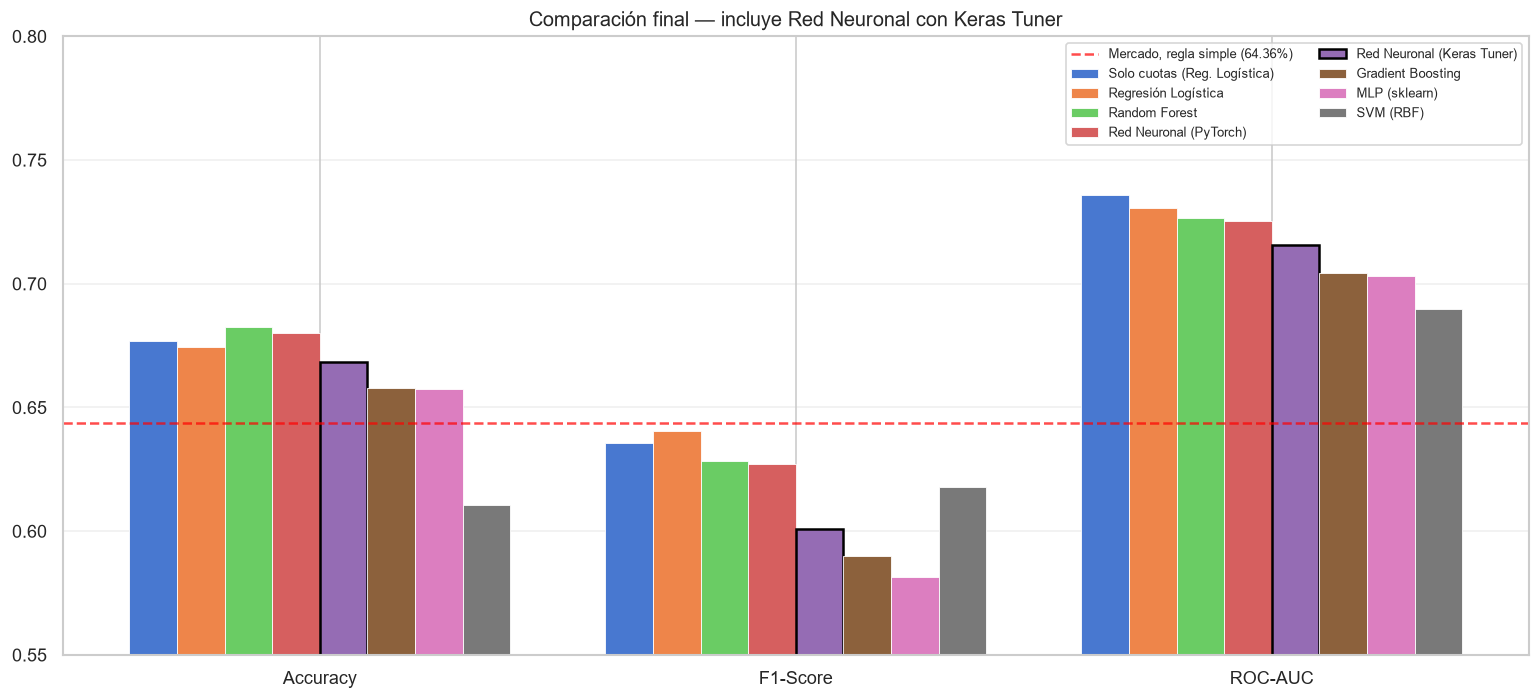

In [8]:
prev = pd.read_csv('resultados/tuning_results_final.csv', index_col='model')
comp = pd.concat([prev, summary_k, summary_ref]).sort_values('roc_auc_mean', ascending=False)
comp.to_csv('resultados/comparacion_con_keras_tuner.csv')

print('COMPARACIÓN FINAL (promedio 7 folds)')
print('=' * 80)
print(f'{"Modelo":<30}{"Accuracy":>13}{"F1":>13}{"ROC-AUC":>13}{"Brier":>12}')
for name, r in comp.iterrows():
    print(f'{name:<30}{r.accuracy_mean:>8.4f}±{r.accuracy_std:.3f}'
          f'{r.f1_score_mean:>8.4f}±{r.f1_score_std:.3f}'
          f'{r.roc_auc_mean:>8.4f}±{r.roc_auc_std:.3f}'
          f'{r.brier_score_mean:>7.4f}')
print(f'{"Mercado (regla simple)":<30}{BASELINE_MERCADO:>8.4f}')

fig, ax = plt.subplots(figsize=(13, 6))
metrics = [('accuracy_mean', 'Accuracy'), ('f1_score_mean', 'F1-Score'), ('roc_auc_mean', 'ROC-AUC')]
x, w = np.arange(len(metrics)), 0.8 / len(comp)
palette = sns.color_palette('muted', len(comp))
for i, (name, r) in enumerate(comp.iterrows()):
    destacar = 'Keras' in name
    ax.bar(x + (i - len(comp)/2 + 0.5) * w, [r[m] for m, _ in metrics], w, label=name,
           color=palette[i], edgecolor='black' if destacar else 'white', linewidth=1.5 if destacar else 0.5)
ax.axhline(BASELINE_MERCADO, color='red', linestyle='--', alpha=0.7, label=f'Mercado, regla simple ({BASELINE_MERCADO*100:.2f}%)')
ax.set_xticks(x); ax.set_xticklabels([l for _, l in metrics])
ax.set_ylim(0.55, 0.80); ax.set_title('Comparación final — incluye Red Neuronal con Keras Tuner')
ax.legend(loc='upper right', fontsize=8, ncol=2); ax.grid(True, alpha=0.3, axis='y')
plt.tight_layout()
plt.savefig('Imagenes/keras_tuner/comparacion_final.png', bbox_inches='tight', dpi=120)
plt.show()

## 7. Evolución por fold

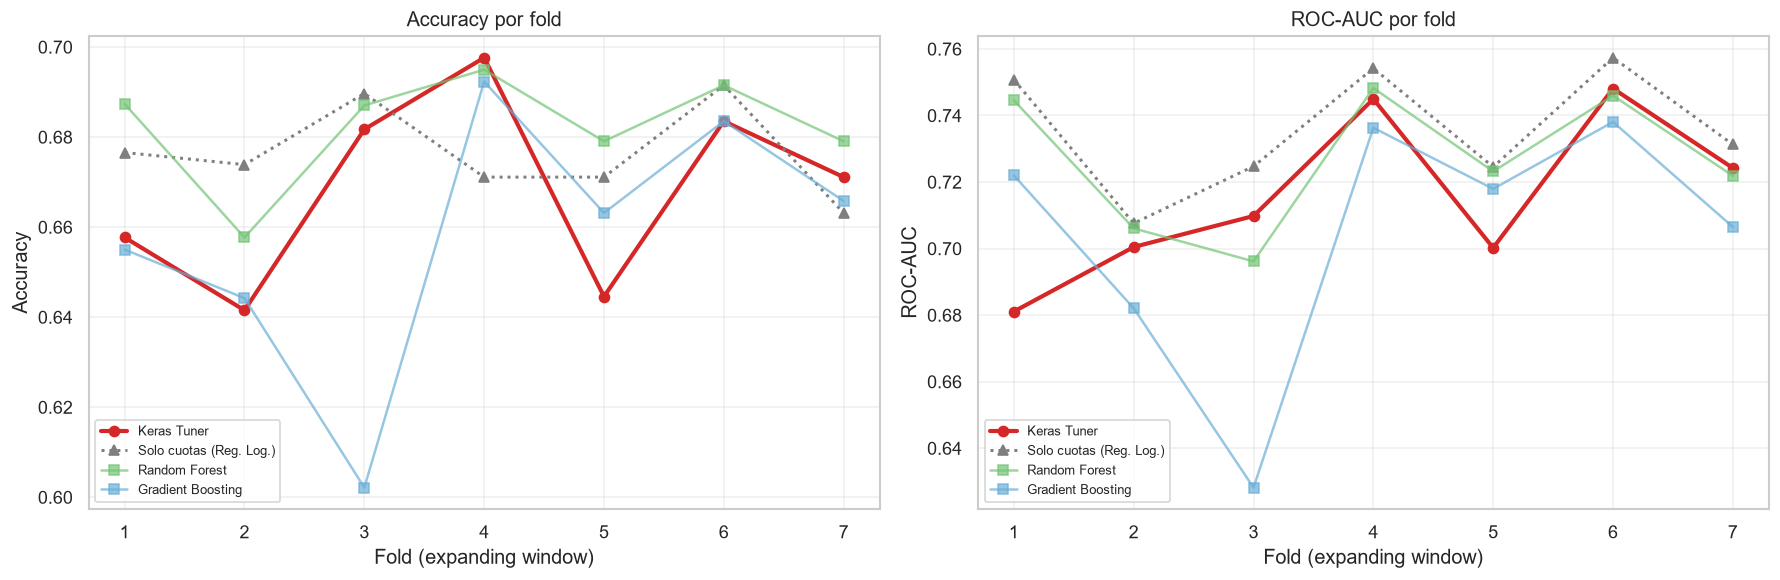

In [9]:
det = pd.read_csv('resultados/tuning_results_detailed.csv')
fig, axes = plt.subplots(1, 2, figsize=(15, 5))
for ax, met, lab in zip(axes, ['accuracy', 'roc_auc'], ['Accuracy', 'ROC-AUC']):
    ax.plot(df_k['fold'], df_k[met], marker='o', lw=2.5, color='#d62728', label='Keras Tuner')
    ax.plot(df_ref['fold'], df_ref[met], marker='^', lw=1.8, color='#7f7f7f', ls=':', label='Solo cuotas (Reg. Log.)')
    for name, col in [('Random Forest', '#74c476'), ('Gradient Boosting', '#6baed6')]:
        s = det[det['model'] == name]
        ax.plot(s['fold'], s[met], marker='s', lw=1.5, alpha=0.7, color=col, label=name)
    ax.set_xlabel('Fold (expanding window)'); ax.set_ylabel(lab)
    ax.set_title(f'{lab} por fold'); ax.legend(fontsize=8); ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig('Imagenes/keras_tuner/evolucion_folds.png', bbox_inches='tight', dpi=120)
plt.show()

## 8. Curvas de entrenamiento (mejor configuración, todos los folds)

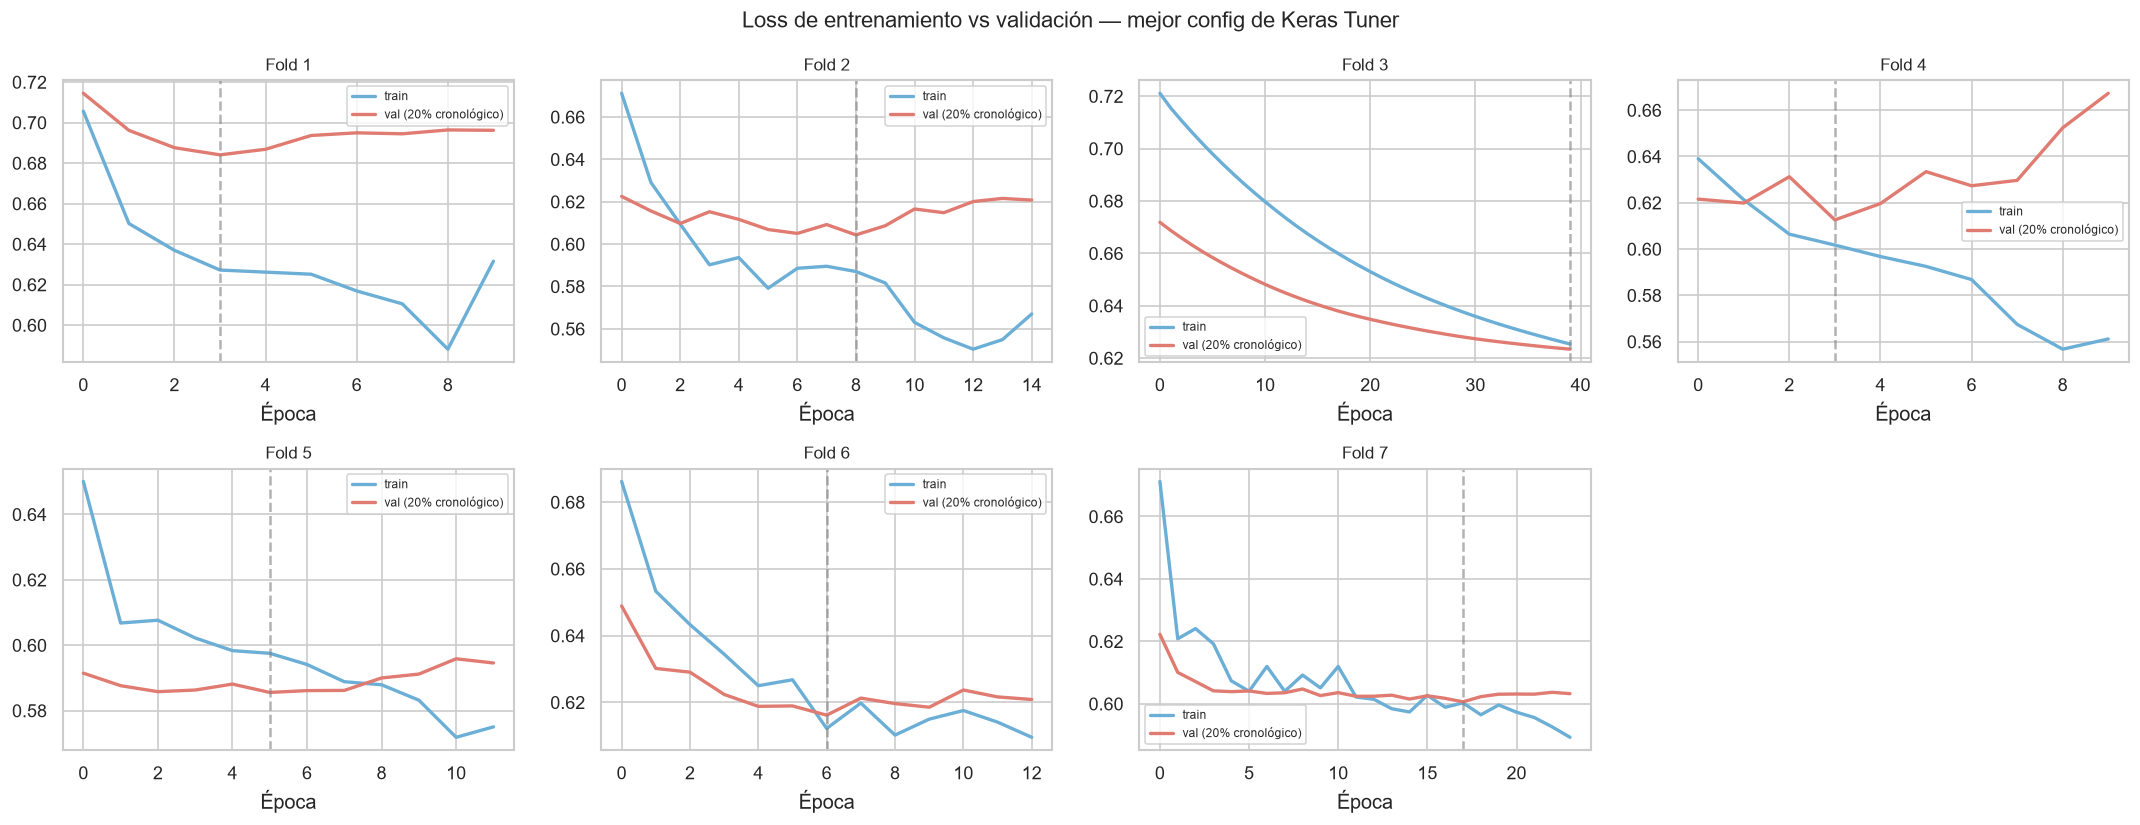

In [10]:
fig, axes = plt.subplots(2, 4, figsize=(18, 7), sharey=False)
for ax, (fold, h) in zip(axes.ravel(), histories.items()):
    ax.plot(h['loss'], label='train', color='#6baed6', lw=2)
    ax.plot(h['val_loss'], label='val (20% cronológico)', color='#e07b71', lw=2)
    ax.axvline(int(np.argmin(h['val_loss'])), color='gray', ls='--', alpha=0.6)
    ax.set_title(f'Fold {fold}', fontsize=10); ax.set_xlabel('Época'); ax.legend(fontsize=7)
axes.ravel()[-1].set_visible(False)
plt.suptitle('Loss de entrenamiento vs validación — mejor config de Keras Tuner', fontsize=13)
plt.tight_layout()
plt.savefig('Imagenes/keras_tuner/curvas_entrenamiento.png', bbox_inches='tight', dpi=120)
plt.show()

## 9. Calibración de probabilidades (todos los folds agregados)

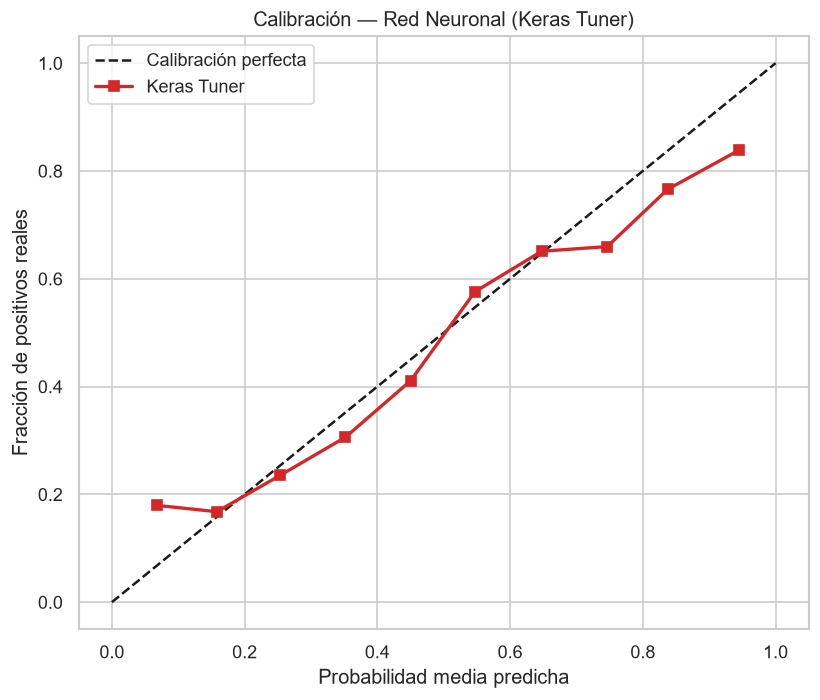

In [11]:
y_all = np.concatenate([v[0] for v in test_preds.values()])
p_all = np.concatenate([v[1] for v in test_preds.values()])
pt, pp = calibration_curve(y_all, p_all, n_bins=10)

fig, ax = plt.subplots(figsize=(7, 6))
ax.plot([0, 1], [0, 1], 'k--', label='Calibración perfecta')
ax.plot(pp, pt, 's-', color='#d62728', lw=2, label='Keras Tuner')
ax.set_xlabel('Probabilidad media predicha'); ax.set_ylabel('Fracción de positivos reales')
ax.set_title('Calibración — Red Neuronal (Keras Tuner)'); ax.legend()
plt.tight_layout()
plt.savefig('Imagenes/keras_tuner/calibracion.png', bbox_inches='tight', dpi=120)
plt.show()

## 10. Resumen final

In [12]:
kt_row = comp.loc['Red Neuronal (Keras Tuner)']
pt_row = comp.loc['Red Neuronal (PyTorch)']
ref_row = comp.loc['Solo cuotas (Reg. Logística)']
print('=' * 72)
print(' RESUMEN — RED NEURONAL CON KERAS TUNER')
print('=' * 72)
print(f' Configuraciones evaluadas por fold (bayesiana): {int(df_k["n_trials"].mean())}')
print(f' Accuracy : {kt_row.accuracy_mean:.4f} ± {kt_row.accuracy_std:.3f}  (PyTorch {pt_row.accuracy_mean:.4f} | solo cuotas {ref_row.accuracy_mean:.4f})')
print(f' F1-Score : {kt_row.f1_score_mean:.4f} ± {kt_row.f1_score_std:.3f}  (PyTorch {pt_row.f1_score_mean:.4f})')
print(f' ROC-AUC  : {kt_row.roc_auc_mean:.4f} ± {kt_row.roc_auc_std:.3f}  (PyTorch {pt_row.roc_auc_mean:.4f} | solo cuotas {ref_row.roc_auc_mean:.4f})')
print(f' Brier    : {kt_row.brier_score_mean:.4f}  (PyTorch {pt_row.brier_score_mean:.4f})')
print(f' Diferencia de accuracy vs. mercado (regla simple): {(kt_row.accuracy_mean - BASELINE_MERCADO)*100:+.2f} puntos')
print(f' Mejor modelo por ROC-AUC: {comp.index[0]}')
print('=' * 72)

 RESUMEN — RED NEURONAL CON KERAS TUNER
 Configuraciones evaluadas por fold (bayesiana): 20
 Accuracy : 0.6682 ± 0.021  (PyTorch 0.6801 | solo cuotas 0.6767)
 F1-Score : 0.6008 ± 0.026  (PyTorch 0.6273)
 ROC-AUC  : 0.7155 ± 0.025  (PyTorch 0.7252 | solo cuotas 0.7358)
 Brier    : 0.2170  (PyTorch 0.2113)
 Diferencia de accuracy vs. mercado (regla simple): +2.46 puntos
 Mejor modelo por ROC-AUC: Solo cuotas (Reg. Logística)
